In [1]:
import numpy as np
from scipy.spatial import voronoi_plot_2d
from scipy.spatial import Voronoi, ConvexHull
import matplotlib.pyplot as plt

def generate_hexagonal_seed(point_number, boxsize, lattice_noise=0):
    """
    Create seed points (Voronoi center) on a controlled or "noisy" (with a bit of noise) hexagonal lattice, and applies periodic boundary conditions.
    TO DO: initialize polarity, angles, momentum, a flag indicating at which stage we are currently in.
    
    Parameters
    -----
    point_number : int
        Number of seed point to create
    boxsize : float
        Length of the axis for observation box (assumed square for now)
    lattice_noise : float
        Intensity of the noise applied to the lattice seed points

    Returns
    -----
    generated_points : ndarray of ndarray
        Array of seed points on a lattice (of coordinates x,y)
    generated_angles : ndarray
        Array of randomly drawn angles in radians
    generated_polarities : ndarray of double
        Array of polarity vectors (cos theta_i, sin theta_i), initialized with random initial values 
    (in the future maybe): flag
    """
    # FIXME Step should be computed and not hard coded
    cpt = 0
    generated_points = np.zeros([int(boxsize)**2,2])

    for y in np.arange(-boxsize/2.0,boxsize/2.0,1):
        if(y % 2 == 0):
            for x in np.arange(-boxsize/2.0,boxsize/2.0,1):
                generated_points[cpt][0] = x
                generated_points[cpt][1] = y               
                cpt = cpt + 1
        else:
            for x in np.arange( (-boxsize/2.0)+0.5,boxsize/2.0,1):
                generated_points[cpt][0] = x
                generated_points[cpt][1] = y               
                cpt = cpt + 1

#    #### XXX : I do not see the point of doing this in the initialization part ####
#    for coord in generated_points:
#        coord[0] = generate_periodic_boundaries(coord[0], boxsize) # x coordinate
#        coord[1] = generate_periodic_boundaries(coord[1], boxsize) # y coordinate
#        # print(coord[0], coord[1])
#    
#
#
#    # ADD ANGLE INITIALISATION, POLARITY, NOISE, ETC.
#    # Angle initialisation for every seed point (initialisation is done in radians)
#    generated_angles = np.random.random(len(generated_points))* 2.0 * np.pi
#    # Generate the associated polarity vectors
#    generated_polarities = generate_every_polarity_vector(generated_angles)
#
    # XXX Temporary return for prototyping
    return generated_points


def hexagonal_lattice_initialization(point_number, boxsize, lattice_noise=0):
    """
    Create seed points (Voronoi center) on an triangular pattern (to give hexagonal cells) and applies periodic boundary conditions.
    TO DO: initialize polarity, angles, momentum, a flag indicating at which stage we are currently in.
    
    Parameters
    -----
    point_number : int
        Number of seed point to create
    boxsize : float
        Length of the axis for observation box (assumed square for now)
    lattice_noise : float
        Intensity of the noise applied to the lattice seed points

    Returns
    -----
    generated_points : ndarray of ndarray
        Array of seed points on a lattice (of coordinates x,y)
    generated_angles : ndarray
        Array of randomly drawn angles in radians
    generated_polarities : ndarray of double
        Array of polarity vectors (cos theta_i, sin theta_i), initialized with random initial values 
    (in the future maybe): flag
    """
    # FIXME Step should be computed and not hard coded
    generated_points = generate_hexagonal_seed(point_number, boxsize, lattice_noise=0)


    # Extremely important : places everyone in the observation box
    # TODO : Maybe find a better name for the function
    for coord in generated_points:
        coord[0] = generate_periodic_boundaries(coord[0], boxsize) # x coordinate
        coord[1] = generate_periodic_boundaries(coord[1], boxsize) # y coordinate
        # print(coord[0], coord[1])
    

    # ADD ANGLE INITIALISATION, POLARITY, NOISE, ETC.
    # Angle initialisation for every seed point (initialisation is done in radians)
    generated_angles = np.random.random(len(generated_points))* 2.0 * np.pi
    # Generate the associated polarity vectors
#    generated_polarities = generate_every_polarity_vector(generated_angles)
    generated_polarities = np.zeros(len(generated_points))
    return generated_points, generated_angles, generated_polarities

def voronoi_finite_polygons_2d(vor, radius=None):
    """
    Reconstruct infinite voronoi regions in a 2D diagram to finite regions.

    Parameters
    ----------
    vor : Voronoi
        Input diagram
    radius : float, optional
        Distance to 'points at infinity'.

    Returns
    -------
    regions : list of lists
        Indices of vertices in each revised Voronoi regions.
        Vertices are sorted counter-clockwise.
    vertices : list of lists
        Coordinates for revised Voronoi vertices. Same as coordinates
        of input vertices, with 'points at infinity' appended to the
        end.

    """

    if vor.points.shape[1] != 2:
        raise ValueError("Requires 2D input")

    new_regions = []
    new_vertices = vor.vertices.tolist()

    center = vor.points.mean(axis=0)
    if radius is None:
        radius = vor.points.ptp().max()*2

    # Construct a map containing all ridges for a given point
    all_ridges = {}
    for (p1, p2), (v1, v2) in zip(vor.ridge_points, vor.ridge_vertices):
        all_ridges.setdefault(p1, []).append((p2, v1, v2))
        all_ridges.setdefault(p2, []).append((p1, v1, v2))

    # Reconstruct infinite regions
    for p1, region in enumerate(vor.point_region):
        vertices = vor.regions[region]

        if all(v >= 0 for v in vertices):
            # finite region
            new_regions.append(vertices)
            continue

        # reconstruct a non-finite region
        ridges = all_ridges[p1]
        new_region = [v for v in vertices if v >= 0]

        for p2, v1, v2 in ridges:
            if v2 < 0:
                v1, v2 = v2, v1
            if v1 >= 0:
                # finite ridge: already in the region
                continue

            # Compute the missing endpoint of an infinite ridge

            t = vor.points[p2] - vor.points[p1] # tangent
            t /= np.linalg.norm(t)
            n = np.array([-t[1], t[0]])  # normal

            midpoint = vor.points[[p1, p2]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, n)) * n
            far_point = vor.vertices[v2] + direction * radius

            new_region.append(len(new_vertices))
            new_vertices.append(far_point.tolist())


        # sort region counterclockwise
        vs = np.asarray([new_vertices[v] for v in new_region])
        c = vs.mean(axis=0)
        angles = np.arctan2(vs[:,1] - c[1], vs[:,0] - c[0])
        new_region = np.array(new_region)[np.argsort(angles)]

        # finish
        new_regions.append(new_region.tolist())

    return new_regions, np.asarray(new_vertices)

def generate_periodic_boundaries(val, box):
    """
    Generates periodic boundaries by translating values to fit inside the observation box.
    
    Inspired by Hiraiwa Tetsuya. Modified because of performance issues. 
    Parameters:
        val: double, coordinate
        box: size of one side of the observation box
    -----
    Returns:
        translated_value: double, coordinate after translation
    
    Note: in CCM.C (program by T.H), this function is called at initialization and [after Runge-Kutta but before polarity time evolution]
    """

    ## Just like in a videogame, when you cross a side of the screen, you appear back on the other side

    # while(val > box/2.0):
    #     # val = val - box
    #     # The above option is correct but time consuming
    #     val = val % box
    # while( val <= -box/2.0):
    #     # val = val + box
    #     # The above option is correct but time consuming
    #     val = val % box

    while(val < -box/2.0 or val > box/2.0):
        if(val > box/2.0 and val < box):
            val = (box % val) * (-1.0)
        elif(val < -box/2.0 and val > -box):
            val = (-box % val) * (-1.0)
        elif(val >= box):
            val = val % box
        elif(val <= box):
            val = val % -box
    return val

def generate_periodic_voronoi_cells_2( points, boxsize):
    """
    Copy the initialized points around the observation box of size "boxsize", over the 8 nearest regions
    C-like version (250+ times faster than the pure python)

    Parameters:
    points : numpy array of arrays
        (x,y) coordinates of the Voronoi centers
    boxsize : float
        Size of a side of the observation box (assumed square-shaped)
    -----
    Returns:
    extended_points : numpy array of arrays
        (x,y) coordinates of the Voronoi centers and their copy
    """

    #Define all the variables
    len_points = len(points)
    DTYPE=np.float64
    # Empty point array to store the original points and three copies
    extended_points_np = np.zeros((len(points)*9,2), dtype=DTYPE)
    extended_points = extended_points_np

    index = 0
    # Copy the original values
    for index in range(len_points):
        extended_points[index][0] = points[index][0]
        extended_points[index][1] = points[index][1]

        # Translate along the y-axis
    for index in range(len_points):
        extended_points[index+len_points][0] = points[index][0]
        extended_points[index+len_points][1] = points[index][1] + boxsize
        extended_points[index+len_points*2][0] = points[index][0]
        extended_points[index+len_points*2][1] = points[index][1] - boxsize

    # Translate along the x-axis
    for index in range(len_points):
        extended_points[index+len_points*3][0] = points[index][0] + boxsize
        extended_points[index+len_points*3][1] = points[index][1]
        extended_points[index+len_points*4][0] = points[index][0] - boxsize
        extended_points[index+len_points*4][1] = points[index][1]

    # Translate along the diagonal
    for index in range(len_points):
        extended_points[index+len_points*5][0] = points[index][0] + boxsize
        extended_points[index+len_points*5][1] = points[index][1] + boxsize

        extended_points[index+len_points*6][0] = points[index][0] - boxsize
        extended_points[index+len_points*6][1] = points[index][1] - boxsize

        extended_points[index+len_points*7][0] = points[index][0] + boxsize
        extended_points[index+len_points*7][1] = points[index][1] - boxsize

        extended_points[index+len_points*8][0] = points[index][0] - boxsize
        extended_points[index+len_points*8][1] = points[index][1] + boxsize

    return extended_points

def initialization(point_number, boxsize):
    """
    Create an array of random seed points (Voronoi center), and applies periodic boundary conditions.
    TO DO: initialize polarity, angles, momentum, a flag indicating at which stage we are currently in.
    
    Parameters
    -----
    point_number : int
        Number of seed point to create
    boxsize : float 
        Length of the axis for observation box (assumed square for now)

    Returns
    -----
    generated_points : ndarray of ndarray
        Array of random seed points (of coordinates x,y)
    generated_angles : ndarray
        Array of randomly drawn angles in radians
    generated_polarities : ndarray of double
        Array of polarity vectors (cos theta_i, sin theta_i), initialized with random initial values 
    (in the future maybe): flag
    """
    # XXX : DEBUG
    generated_points = np.random.rand(point_number, 2) * boxsize - (boxsize * 0.5 * 0.5)
    # XXX : With a Poisson distribution
    # generated_points = np.random.poisson(lam=1.0,size=(point_number, 2)) * boxsize - (boxsize * 0.5 * 0.5)
    # generated_points = (2* np.random.rand(point_number, 2) - 1) * boxsize * 0.5
    # DEBUG 
    # generated_points = generated_points * 10
    # print(generated_points)
    # print('-'*10)

    # Extremely important : places everyone in the observation box
    # TODO : Maybe find a better name for the function
    for coord in generated_points:
        coord[0] = generate_periodic_boundaries(coord[0], boxsize) # x coordinate
        coord[1] = generate_periodic_boundaries(coord[1], boxsize) # y coordinate
        # print(coord[0], coord[1])
    


    # ADD ANGLE INITIALISATION, POLARITY, NOISE, ETC.
    # Angle initialisation for every seed point (initialisation is done in radians)
    generated_angles = np.random.random(len(generated_points))* 2.0 * np.pi
    # Generate the associated polarity vectors
#    generated_polarities = generate_every_polarity_vector(generated_angles)
    generated_polarities = np.zeros(len(generated_points))
    return generated_points, generated_angles, generated_polarities



In [2]:
boxsize = 10
point_number = 100
#np.random.seed(29308)
np.random.seed(15)
points = hexagonal_lattice_initialization(point_number, boxsize)[0]
#points = initialization(100,boxsize)[0]
extended_points = generate_periodic_voronoi_cells_2(points,boxsize)
vor = Voronoi(extended_points)
regions, vertices = voronoi_finite_polygons_2d(vor)


In [3]:
def plot_polygons(vor, regions, vertices):
    """
    Graphical function to plot colored polygons within a box

    Note that while the Voronoi regions are finite, they may still go beyond the box 
    Parameters:
    vor : A Voronoi object
    regions : list of lists
        Indices of vertices in each revised Voronoi regions.
    vertices : list of lists
        Coordinates for revised Voronoi vertices. Same as coordinates
        of input vertices, with 'points at infinity' appended to the
        end. 
    """
    for region in regions:
        polygon = vertices[region]
        # plt.fill(*zip(*polygon), alpha=0.4) # Color the polygons
        plt.plot(polygon[:,0], polygon[:,1], '--k')
        ## Uncomment the lines below for a nicer display in an area of interest
        # plt.xlim(vor.min_bound[0] - 0.1, vor.max_bound[0] + 0.1) # Forces display in a box
        # plt.ylim(vor.min_bound[1] - 0.1, vor.max_bound[1] + 0.1) # Forces display in a box

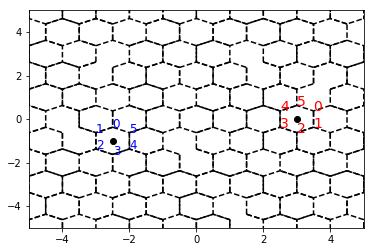

In [4]:
def unproperly_sorted_vertices():
    boxsize = 10
    point_number = 100
    
    # Fix the seed for reproducibility
    np.random.seed(15)
    points = hexagonal_lattice_initialization(point_number, boxsize)[0]
    #points = initialization(100,boxsize)[0]
    extended_points = generate_periodic_voronoi_cells_2(points,boxsize)
    vor = Voronoi(extended_points)
    regions, vertices = voronoi_finite_polygons_2d(vor)

    plot_polygons(vor, regions, vertices)
    plt.xlim(-boxsize/2.0, boxsize/2.0)
    plt.ylim(-boxsize/2.0, boxsize/2.0)
    
    # Example of a region sorted counter-clockwisely
    region_to_plot = 42
    plt.plot(points[region_to_plot,0],points[region_to_plot, 1], 'ko')
    for index, vertex in enumerate(vertices[regions[region_to_plot]]):
        plt.text(vertex[0], vertex[1], str(index), color='blue', fontsize=12)


    # Example of a region sorted clockwisely
    region_to_plot = 58
    plt.plot(points[region_to_plot,0],points[region_to_plot, 1], 'ko')
    for index, vertex in enumerate(vertices[regions[region_to_plot]]):
        plt.text(vertex[0], vertex[1], str(index), color='red', fontsize=14)
    
    plt.show()

# Call the function
unproperly_sorted_vertices()

In [5]:
vertices

array([[-14.5  ,  -3.625],
       [-14.   ,  -3.375],
       [-14.5  ,  -7.625],
       ...,
       [ -6.5  ,  72.625],
       [ -6.5  ,  72.625],
       [ -5.5  ,  72.625]])

In [6]:
for region in regions:
    print(vertices[region])

[[-4.    -5.375]
 [-4.    -4.625]
 [-4.5   -4.375]
 [-5.    -4.625]
 [-5.    -5.375]
 [-4.5   -5.625]]
[[-3.5   -5.625]
 [-3.    -5.375]
 [-3.    -4.625]
 [-3.5   -4.375]
 [-4.    -4.625]
 [-4.    -5.375]]
[[-3.    -4.625]
 [-2.5   -4.375]
 [-2.    -4.625]
 [-2.    -5.375]
 [-2.5   -5.625]
 [-3.    -5.375]]
[[-2.    -5.375]
 [-2.    -4.625]
 [-1.5   -4.375]
 [-1.    -4.625]
 [-1.    -5.375]
 [-1.5   -5.625]]
[[-0.5   -5.625]
 [-1.    -5.375]
 [-1.    -4.625]
 [-0.5   -4.375]
 [ 0.    -4.625]
 [ 0.    -5.375]]
[[ 0.    -5.375]
 [ 0.    -4.625]
 [ 0.5   -4.375]
 [ 1.    -4.625]
 [ 1.    -5.375]
 [ 0.5   -5.625]]
[[ 1.5   -4.375]
 [ 2.    -4.625]
 [ 2.    -5.375]
 [ 1.5   -5.625]
 [ 1.    -5.375]
 [ 1.    -4.625]]
[[ 2.    -4.625]
 [ 2.5   -4.375]
 [ 3.    -4.625]
 [ 3.    -5.375]
 [ 2.5   -5.625]
 [ 2.    -5.375]]
[[ 4.    -4.625]
 [ 3.5   -4.375]
 [ 3.    -4.625]
 [ 3.    -5.375]
 [ 3.5   -5.625]
 [ 4.    -5.375]]
[[ 4.5   -5.625]
 [ 4.    -5.375]
 [ 4.    -4.625]
 [ 4.5   -4.375]
 [ 5.

 [9.5   2.375]]
[[10.     1.375]
 [ 9.5    1.625]
 [ 9.5    2.375]
 [10.     2.625]
 [10.5    2.375]
 [10.5    1.625]]
[[11.     1.375]
 [11.5    1.625]
 [11.5    2.375]
 [11.     2.625]
 [10.5    2.375]
 [10.5    1.625]]
[[12.     2.625]
 [11.5    2.375]
 [11.5    1.625]
 [12.     1.375]
 [12.5    1.625]
 [12.5    2.375]]
[[12.5    2.375]
 [12.5    1.625]
 [13.     1.375]
 [13.5    1.625]
 [13.5    2.375]
 [13.     2.625]]
[[14.     1.375]
 [15.25   2.   ]
 [14.     2.625]
 [13.5    2.375]
 [13.5    1.625]]
[[6.    3.375]
 [6.    2.625]
 [5.5   2.375]
 [5.    2.625]
 [5.    3.375]
 [5.5   3.625]]
[[6.5   3.625]
 [7.    3.375]
 [7.    2.625]
 [6.5   2.375]
 [6.    2.625]
 [6.    3.375]]
[[7.5   3.625]
 [8.    3.375]
 [8.    2.625]
 [7.5   2.375]
 [7.    2.625]
 [7.    3.375]]
[[8.    3.375]
 [8.5   3.625]
 [9.    3.375]
 [9.    2.625]
 [8.5   2.375]
 [8.    2.625]]
[[10.     3.375]
 [ 9.5    3.625]
 [ 9.     3.375]
 [ 9.     2.625]
 [ 9.5    2.375]
 [10.     2.625]]
[[11.     3.375]
 [

[[7.5   6.375]
 [7.5   5.625]
 [8.    5.375]
 [8.5   5.625]
 [8.5   6.375]
 [8.    6.625]]
[[8.5   6.375]
 [9.    6.625]
 [9.5   6.375]
 [9.5   5.625]
 [9.    5.375]
 [8.5   5.625]]
[[10.5    5.625]
 [10.5    6.375]
 [10.     6.625]
 [ 9.5    6.375]
 [ 9.5    5.625]
 [10.     5.375]]
[[10.5    5.625]
 [11.     5.375]
 [11.5    5.625]
 [11.5    6.375]
 [11.     6.625]
 [10.5    6.375]]
[[11.5    6.375]
 [11.5    5.625]
 [12.     5.375]
 [12.5    5.625]
 [12.5    6.375]
 [12.     6.625]]
[[13.5    5.625]
 [13.5    6.375]
 [13.     6.625]
 [12.5    6.375]
 [12.5    5.625]
 [13.     5.375]]
[[13.5    5.625]
 [13.5    6.375]
 [14.     6.625]
 [15.25   6.   ]
 [14.     5.375]]
[[5.5   7.625]
 [5.    7.375]
 [5.    6.625]
 [5.5   6.375]
 [6.    6.625]
 [6.    7.375]]
[[6.    7.375]
 [6.    6.625]
 [6.5   6.375]
 [7.    6.625]
 [7.    7.375]
 [6.5   7.625]]
[[7.5   6.375]
 [7.    6.625]
 [7.    7.375]
 [7.5   7.625]
 [8.    7.375]
 [8.    6.625]]
[[8.5   6.375]
 [9.    6.625]
 [9.    7.375]
 [

 [-14.     11.375]]
[[-14.     10.625]
 [-14.     11.375]
 [-13.5    11.625]
 [-13.     11.375]
 [-13.     10.625]
 [-13.5    10.375]]
[[-13.     10.625]
 [-12.5    10.375]
 [-12.     10.625]
 [-12.     11.375]
 [-12.5    11.625]
 [-13.     11.375]]
[[-12.     10.625]
 [-11.5    10.375]
 [-11.     10.625]
 [-11.     11.375]
 [-11.5    11.625]
 [-12.     11.375]]
[[-10.5    10.375]
 [-11.     10.625]
 [-11.     11.375]
 [-10.5    11.625]
 [-10.     11.375]
 [-10.     10.625]]
[[-10.     10.625]
 [-10.     11.375]
 [ -9.5    11.625]
 [ -9.     11.375]
 [ -9.     10.625]
 [ -9.5    10.375]]
[[-8.    10.625]
 [-8.5   10.375]
 [-9.    10.625]
 [-9.    11.375]
 [-8.5   11.625]
 [-8.    11.375]]
[[-7.    10.625]
 [-7.5   10.375]
 [-8.    10.625]
 [-8.    11.375]
 [-7.5   11.625]
 [-7.    11.375]]
[[-6.5   11.625]
 [-7.    11.375]
 [-7.    10.625]
 [-6.5   10.375]
 [-6.    10.625]
 [-6.    11.375]]
[[-6.    11.375]
 [-6.    10.625]
 [-5.5   10.375]
 [-5.    10.625]
 [-5.    11.375]
 [-5.5   11

In [7]:
for region in regions:
    print(vertices[region, 0][0])
    print('='*10)

-4.0
-3.5
-3.0
-2.0
-0.5
0.0
1.5
2.0
4.0
4.5
-5.5
-3.5
-3.0
-2.5
-0.5
0.5
1.5
1.5
3.5
4.0
-5.0
-3.0
-2.5
-1.5
-1.0
0.5
1.0
2.0
3.5
4.5
-5.5
-3.5
-2.5
-2.5
-1.0
0.0
0.5
1.5
2.5
4.5
-4.5
-3.5
-2.5
-1.0
0.0
0.0
1.0
2.0
3.5
4.5
-4.5
-3.5
-2.5
-2.0
-1.0
-0.5
1.0
2.0
3.5
4.0
-4.0
-3.0
-3.0
-2.0
-1.0
0.0
2.0
3.0
4.0
4.0
-5.5
-3.5
-3.0
-2.5
-0.5
-0.5
1.5
2.0
3.0
4.0
-4.0
-3.0
-3.0
-2.0
-0.5
1.0
2.0
2.0
3.0
4.5
-5.5
-3.5
-2.5
-2.0
-1.5
-0.5
1.5
2.0
3.0
4.5
-4.5
-4.0
-2.5
-1.5
-0.5
0.0
2.0
2.0
4.0
4.5
-5.5
-4.0
-3.5
-1.5
-1.0
-0.5
1.5
2.0
3.0
4.0
-4.5
-3.0
-2.5
-1.5
-1.0
0.5
2.0
3.0
3.0
4.0
-4.5
-3.5
-2.5
-2.5
-1.5
-0.5
0.5
2.5
2.5
3.5
-4.0
-3.0
-2.5
-2.0
-1.0
0.0
1.5
3.0
3.5
5.0
-5.0
-4.0
-3.0
-2.0
-1.0
-0.5
0.5
2.0
3.5
4.5
-4.0
-4.0
-2.0
-1.5
-0.5
0.0
2.0
2.0
4.0
4.5
-5.5
-4.0
-2.5
-1.5
-1.5
0.5
1.0
2.0
3.5
4.5
-4.0
-3.5
-2.5
-1.5
0.0
1.0
1.0
3.0
4.0
4.5
-5.5
-4.5
-3.5
-2.5
-1.5
-0.5
0.5
1.5
2.5
3.5
-5.0
-4.0
-3.0
-2.0
-1.0
0.0
1.0
2.0
3.0
4.0
-4.5
-4.5
-3.5
-1.5
-1.5
0.0
1.0
2.0
3.5
4.0
-4.5


10.0
10.0
11.5
12.0
13.5
14.0
4.5
5.5
6.5
8.0
8.5
9.5
11.5
11.5
12.5
13.5
5.5
6.5
7.5
8.5
10.0
10.5
11.0
13.0
13.0
14.0
5.5
5.5
6.5
7.5
8.5
10.5
10.5
11.5
13.5
14.0
5.5
6.5
7.0
8.0
10.0
10.0
11.0
13.0
14.0
14.0
4.5
5.5
6.5
7.5
9.5
9.5
10.5
11.5
13.0
14.0
5.5
6.0
7.0
8.0
9.5
10.5
11.5
12.5
13.0
14.0
4.5
5.5
6.5
7.5
8.5
9.5
10.5
11.5
12.5
13.5
-67.27120426899504
-14.0
-13.0
-12.0
-11.0
-10.0
-9.0
-8.0
-7.0
-6.0
-67.27120426899504
-13.5
-12.5
-12.0
-11.0
-9.5
-8.5
-7.5
-6.5
-5.5
-14.0
-13.5
-12.0
-11.5
-10.0
-9.5
-8.0
-7.0
-6.0
-5.0
-74.75
-13.5
-13.0
-11.5
-11.0
-9.5
-9.5
-7.5
-7.0
-5.5
-14.0
-13.0
-12.0
-11.5
-11.0
-9.0
-8.5
-7.5
-6.0
-5.5
-74.75
-13.5
-12.5
-11.5
-11.5
-10.5
-8.5
-8.5
-6.5
-5.5
-14.0
-13.0
-12.0
-11.5
-11.0
-9.0
-8.5
-7.5
-6.0
-5.5
-74.75
-14.0
-12.5
-12.0
-11.5
-9.5
-8.5
-7.5
-6.5
-5.5
-14.0
-13.0
-12.0
-11.0
-10.0
-10.0
-8.0
-7.0
-6.0
-5.5
-74.75
-13.5
-13.0
-12.5
-10.5
-10.0
-9.0
-8.5
-7.0
-5.5
5.0
6.0
7.0
8.0
9.0
10.0
11.0
12.0
13.0
14.0
4.5
6.5
7.5
8.5
9.5
10.5
11

In [8]:
def is_sorted_counterclockwise(regions, vertices):
    """
    Compute the determinant of the orientation matrix for three vertices per region of a simple convex polygon.
    If positive, the polygon is sorted counterclockwise. Otherwise it is sorted clockwise (assuming there is self intersection or hole in the polygon)
    
    Parameters:
    -----
    # TODO

    Returns:
    -----
    #TODO
    sorted_clockwise_truth_table: np array
        Contains True if the determinant is positive, False otherwise
    """
    
    # Get 3 points by region
#    points_list = np.zeros([len(regions) * 3, 2])
    determinants_table = np.zeros(len(regions))
    for index, region in enumerate(regions):
        # FIXME (maybe) : Mnemonics for easier manipulation, maybe costly. Replace them with direct call to vertices if needed.
        x_A = vertices[region, 0][0]
        x_B = vertices[region, 0][1]
        x_C = vertices[region, 0][2]
        y_A = vertices[region, 1][0]
        y_B = vertices[region, 1][1]
        y_C = vertices[region, 1][2]
        determinants_table[index] = (x_B - x_A) * (y_C - y_A) - (x_C - x_A) * (y_B - y_A) 

    # Puts True if positive, False otherwise
    # If the determinant is zero, this would mean that the three vertices are on a line.
#    sorted_clockwise_truth_table = np.greater_equal(determinants_table,0)
    sorted_counterclockwise_truth_table = determinants_table >= 0
    return sorted_counterclockwise_truth_table


In [9]:
def sort_vertices_counterclockwise(regions, vertices, sorted_counterclockwise_truth_table):
    """
    Reverse the regions where sorted_clockwise_truth_table is false. 
    
    Parameters:
    -----
    # TODO

    Returns:
    -----
    regions_sorted_counterclockwise: list of lists
    """
    
    regions_sorted_counterclockwise = [ regions[i][::-1] if not sorted_counterclockwise_truth_table[i] else regions[i] for i in range(len(regions))]
    
#    assert np.all(is_sorted_counterclockwise(regions_sorted_counterclockwise, vertices)), "Didn't properly sort all the regions"
    
    return regions_sorted_counterclockwise

In [10]:
sorted_counterclockwise_truth_table = is_sorted_counterclockwise(regions, vertices)
len(sorted_counterclockwise_truth_table)
# With the values tested before, this is coherent
print("42 should be True : {}".format(sorted_counterclockwise_truth_table[42]))
print("58 should be False : {}".format(sorted_counterclockwise_truth_table[58]))
print('-'*10 + 'Testing the ~ operator for reversing truth tables' + '-'*10)
print("~42 should be False : {}".format(~sorted_counterclockwise_truth_table[42]))
print("~58 should be True : {}".format(~sorted_counterclockwise_truth_table[58]))

###############################

#print(sorted_counterclockwise_truth_table)

42 should be True : True
58 should be False : False
----------Testing the ~ operator for reversing truth tables----------
~42 should be False : False
~58 should be True : True


In [11]:
%timeit is_sorted_counterclockwise(regions, vertices)

27 ms ± 5.39 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [12]:
#%timeit det_table > 0

#%timeit np.greater(det_table,0)

Is everything sorted BEFORE : False
Is everything sorted AFTER using sort_vertices_counterclockwise : True


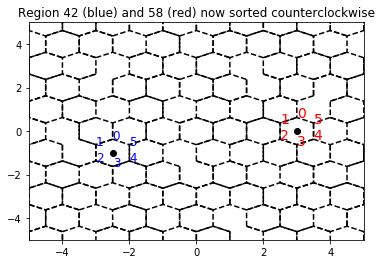

In [13]:
#print(all_cclw)
### Tests if all the regions are properly sorted ###
# Before
print("Is everything sorted BEFORE : {}".format(np.all(sorted_counterclockwise_truth_table)))
# After
regions_all_cclw = sort_vertices_counterclockwise(regions, vertices, sorted_counterclockwise_truth_table)
print("Is everything sorted AFTER using sort_vertices_counterclockwise : {}".format(np.all(is_sorted_counterclockwise(regions_all_cclw,vertices))))

### Plot it to confirm ###

plot_polygons(vor, regions_all_cclw, vertices)
plt.title("Region 42 (blue) and 58 (red) now sorted counterclockwise")
plt.xlim(-boxsize/2.0, boxsize/2.0)
plt.ylim(-boxsize/2.0, boxsize/2.0)

# Example of a region sorted counter-clockwisely
region_to_plot = 42
plt.plot(points[region_to_plot,0],points[region_to_plot, 1], 'ko')
for index, vertex in enumerate(vertices[regions_all_cclw[region_to_plot]]):
    plt.text(vertex[0], vertex[1], str(index), color='blue', fontsize=12)


# Example of a region sorted clockwisely initially but now sorted counter-clockwisely
region_to_plot = 58
plt.plot(points[region_to_plot,0],points[region_to_plot, 1], 'ko')
for index, vertex in enumerate(vertices[regions_all_cclw[region_to_plot]]):
    plt.text(vertex[0], vertex[1], str(index), color='red', fontsize=14)

plt.show()

In [14]:
########### TEST IF voronoi_finite_polygons_2d is fixed or not
def voronoi_finite_polygons_2d_fixed(vor, radius=None):
    """
    Reconstruct infinite voronoi regions in a 2D diagram to finite regions.

    Parameters
    ----------
    vor : Voronoi
        Input diagram
    radius : float, optional
        Distance to 'points at infinity'.

    Returns
    -------
    regions : list of lists
        Indices of vertices in each revised Voronoi regions.
        Vertices are sorted counter-clockwise.
    vertices : list of lists
        Coordinates for revised Voronoi vertices. Same as coordinates
        of input vertices, with 'points at infinity' appended to the
        end.

    """

    if vor.points.shape[1] != 2:
        raise ValueError("Requires 2D input")

    new_regions = []
    new_vertices = vor.vertices.tolist()

    center = vor.points.mean(axis=0)
    if radius is None:
        radius = vor.points.ptp().max()*2

    # Construct a map containing all ridges for a given point
    all_ridges = {}
    for (p1, p2), (v1, v2) in zip(vor.ridge_points, vor.ridge_vertices):
        all_ridges.setdefault(p1, []).append((p2, v1, v2))
        all_ridges.setdefault(p2, []).append((p1, v1, v2))

    # Reconstruct infinite regions
    for p1, region in enumerate(vor.point_region):
        vertices = vor.regions[region]

        if all(v >= 0 for v in vertices):
            # finite region
            new_regions.append(vertices)
            continue

        # reconstruct a non-finite region
        ridges = all_ridges[p1]
        new_region = [v for v in vertices if v >= 0]

        for p2, v1, v2 in ridges:
            if v2 < 0:
                v1, v2 = v2, v1
            if v1 >= 0:
                # finite ridge: already in the region
                continue

            # Compute the missing endpoint of an infinite ridge

            t = vor.points[p2] - vor.points[p1] # tangent
            t /= np.linalg.norm(t)
            n = np.array([-t[1], t[0]])  # normal

            midpoint = vor.points[[p1, p2]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, n)) * n
            far_point = vor.vertices[v2] + direction * radius

            new_region.append(len(new_vertices))
            new_vertices.append(far_point.tolist())


        # sort region counterclockwise
        vs = np.asarray([new_vertices[v] for v in new_region])
        c = vs.mean(axis=0)
        angles = np.arctan2(vs[:,1] - c[1], vs[:,0] - c[0])
        new_region = np.array(new_region)[np.argsort(angles)]

        # finish
        new_regions.append(new_region.tolist())
        
        ### FIXME : check if every polygon is properly sorted counterclockwise. Expansiiiive
        sorted_counterclockwise_truth_table = is_sorted_counterclockwise(new_regions, np.asarray(new_vertices))
        new_regions = sort_vertices_counterclockwise(new_regions, np.asarray(new_vertices), sorted_counterclockwise_truth_table)

    return new_regions, np.asarray(new_vertices)

In [15]:
### Regenerate a test ###
boxsize = 10
point_number = 100
#np.random.seed(29308)
np.random.seed(15)
points = hexagonal_lattice_initialization(point_number, boxsize)[0]
#points = initialization(100,boxsize)[0]
extended_points = generate_periodic_voronoi_cells_2(points,boxsize)
vor = Voronoi(extended_points)
regions_old, vertices_old = voronoi_finite_polygons_2d(vor)
regions_fixed, vertices_fixed = voronoi_finite_polygons_2d_fixed(vor)
print(len(regions_fixed))

# With the old sorting function
print(np.all(is_sorted_counterclockwise(regions_old,vertices_old)))
# With a patch applied at the end
print(np.all(is_sorted_counterclockwise(regions_fixed,vertices_fixed)))

900
False
True


In [16]:
%timeit voronoi_finite_polygons_2d(vor)

32 ms ± 9.8 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
%timeit voronoi_finite_polygons_2d_fixed(vor)

1.69 s ± 486 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [18]:
########### TEST IF voronoi_finite_polygons_3d is fixed or not
def voronoi_finite_polygons_2d_reworked(vor, radius=None):
    """
    Reconstruct infinite voronoi regions in a 2D diagram to finite regions.

    Parameters
    ----------
    vor : Voronoi
        Input diagram
    radius : float, optional
        Distance to 'points at infinity'.

    Returns
    -------
    regions : list of lists
        Indices of vertices in each revised Voronoi regions.
        Vertices are sorted counter-clockwise.
    vertices : list of lists
        Coordinates for revised Voronoi vertices. Same as coordinates
        of input vertices, with 'points at infinity' appended to the
        end.

    """

    if vor.points.shape[1] != 2:
        raise ValueError("Requires 2D input")

    new_regions = []
    new_vertices = vor.vertices.tolist()

    center = vor.points.mean(axis=0)
    if radius is None:
        radius = vor.points.ptp().max()*2

    # Construct a map containing all ridges for a given point
    all_ridges = {}
    for (p1, p2), (v1, v2) in zip(vor.ridge_points, vor.ridge_vertices):
        all_ridges.setdefault(p1, []).append((p2, v1, v2))
        all_ridges.setdefault(p2, []).append((p1, v1, v2))

    # Reconstruct infinite regions
    for p1, region in enumerate(vor.point_region):
        vertices = vor.regions[region]

        if all(v >= 0 for v in vertices):
            # finite region
            new_regions.append(vertices)
            continue

        # reconstruct a non-finite region
        ridges = all_ridges[p1]
        new_region = [v for v in vertices if v >= 0]

        for p2, v1, v2 in ridges:
            if v2 < 0:
                v1, v2 = v2, v1
            if v1 >= 0:
                # finite ridge: already in the region
                continue

            # Compute the missing endpoint of an infinite ridge

            t = vor.points[p2] - vor.points[p1] # tangent
            t /= np.linalg.norm(t)
            n = np.array([-t[1], t[0]])  # normal

            midpoint = vor.points[[p1, p2]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, n)) * n
            far_point = vor.vertices[v2] + direction * radius

            new_region.append(len(new_vertices))
            new_vertices.append(far_point.tolist())


        # sort region counterclockwise
#        vs = np.asarray([new_vertices[v] for v in new_region])
#        print("PRINT VS : \n {}".format(vs))
#        c = vs.mean(axis=0)
#        angles = np.arctan2(vs[:,1] - c[1], vs[:,0] - c[0])
#        new_region = np.array(new_region)[np.argsort(angles)]
#        print("len(c) : {}, len(vs) : {}, len(angles) : {}, len(new_region) : {}".format(len(c),len(vs), len(angles), len(new_region)))
#        assert len(vs)==len(angles) and len(angles) == len(new_region), "Length mismatch"
        # print(angles)
        # finish
        new_regions.append(new_region)
#        new_regions.append(new_region) 
        ### FIXME : check if every polygon is properly sorted counterclockwise.
    sorted_counterclockwise_truth_table = is_sorted_counterclockwise(new_regions, np.asarray(new_vertices))
#    print(sorted_counterclockwise_truth_table)
    # HACK 
#    for index, truth in enumerate(sorted_counterclockwise_truth_table):
#        if not truth:
#            new_regions[index] = new_regions[index][::-1]
            
    # Check if everything has been properly sorted
    sorted_counterclockwise_truth_table_2 = is_sorted_counterclockwise(new_regions, np.asarray(new_vertices))
#    print('-'*30 + '\n{}'.format(sorted_counterclockwise_truth_table))
#    assert np.all(is_sorted_counterclockwise(new_regions, np.asarray(new_vertices))), "Still not entirely sorted"
    new_regions = sort_vertices_counterclockwise(new_regions, np.asarray(new_vertices), sorted_counterclockwise_truth_table)

    return new_regions, np.asarray(new_vertices)

In [19]:
def create_test_vor_hex_reworked(boxsize=10, point_number=100,random_seed=15135):
    """
    Convenience function for generating reproducible tests 
    """
    np.random.seed(random_seed)
    points = hexagonal_lattice_initialization(point_number, boxsize)[0]
    extended_points = generate_periodic_voronoi_cells_2(points,boxsize)
    vor = Voronoi(extended_points)
    regions, vertices =  voronoi_finite_polygons_2d_reworked(vor)
    print(len(regions))
    print("Is everything sorted counterclockwisely :")
    print(np.all(is_sorted_counterclockwise(regions, vertices)))
#    print("Is the observation box sorted counterclockwisely :")
#    print(np.all(is_sorted_counterclockwise(regions[0:point_number], vertices)))
    
    assert np.all(is_sorted_counterclockwise(regions[0:point_number], vertices)), "The observation box is not sorted counterclockwise"
    
    return boxsize, point_number, points, extended_points, vor, regions, vertices 
    

900
Is everything sorted counterclockwisely :
False


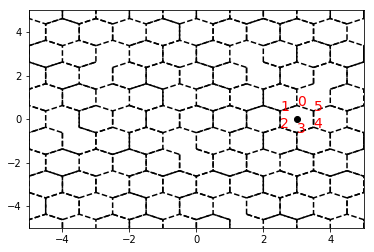

In [20]:
boxsize, point_number, points, extended_points, vor, regions, vertices = create_test_vor_hex_reworked()

plot_polygons(vor, regions_all_cclw, vertices)
plt.xlim(-boxsize/2.0, boxsize/2.0)
plt.ylim(-boxsize/2.0, boxsize/2.0)

# Example of a region sorted clockwisely
region_to_plot = 58
plt.plot(points[region_to_plot,0],points[region_to_plot, 1], 'ko')
for index, vertex in enumerate(vertices[regions[region_to_plot]]):
    plt.text(vertex[0], vertex[1], str(index), color='red', fontsize=14)



In [21]:
########### TEST IF voronoi_finite_polygons_3d is fixed or not
def voronoi_finite_polygons_2d_refactored(vor, point_number, radius=None):
    """
    Reconstruct infinite voronoi regions in a 2D diagram to finite regions.

    Parameters
    ----------
    vor : Voronoi
        Input diagram
    radius : float, optional
        Distance to 'points at infinity'.

    Returns
    -------
    regions : list of lists
        Indices of vertices in each revised Voronoi regions.
        Vertices are sorted counter-clockwise.
    vertices : list of lists
        Coordinates for revised Voronoi vertices. Same as coordinates
        of input vertices, with 'points at infinity' appended to the
        end.

    """

    if vor.points.shape[1] != 2:
        raise ValueError("Requires 2D input")

    new_regions = []
    new_vertices = vor.vertices.tolist()

    center = vor.points.mean(axis=0)
    if radius is None:
        radius = vor.points.ptp().max()*2

    # Construct a map containing all ridges for a given point
    all_ridges = {}
    for (p1, p2), (v1, v2) in zip(vor.ridge_points, vor.ridge_vertices):
        all_ridges.setdefault(p1, []).append((p2, v1, v2))
        all_ridges.setdefault(p2, []).append((p1, v1, v2))

    # Reconstruct infinite regions
    for p1, region in enumerate(vor.point_region):
        vertices = vor.regions[region]

        if all(v >= 0 for v in vertices):
            # finite region
            new_regions.append(vertices)
            continue

        # reconstruct a non-finite region
        ridges = all_ridges[p1]
        new_region = [v for v in vertices if v >= 0]

        for p2, v1, v2 in ridges:
            if v2 < 0:
                v1, v2 = v2, v1
            if v1 >= 0:
                # finite ridge: already in the region
                continue

            # Compute the missing endpoint of an infinite ridge

            t = vor.points[p2] - vor.points[p1] # tangent
            t /= np.linalg.norm(t)
            n = np.array([-t[1], t[0]])  # normal

            midpoint = vor.points[[p1, p2]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, n)) * n
            far_point = vor.vertices[v2] + direction * radius

            new_region.append(len(new_vertices))
            new_vertices.append(far_point.tolist())

        new_regions.append(new_region)
        ### FIXME : check if every polygon is properly sorted counterclockwise.
        
    # Check if everything has been properly sorted
    sorted_counterclockwise_truth_table = is_sorted_counterclockwise(new_regions[0:point_number], np.asarray(new_vertices))
    new_regions = sort_vertices_counterclockwise(new_regions[0:point_number], np.asarray(new_vertices), sorted_counterclockwise_truth_table)

    return new_regions, np.asarray(new_vertices)

900
Is everything sorted counterclockwisely :
False


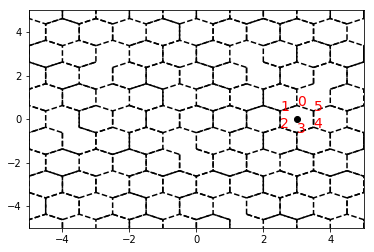

In [22]:
def create_test_vor_hex_refactored(boxsize=10, point_number=100,random_seed=15):
    """
    Convenience function for generating reproducible tests 
    """
    np.random.seed(random_seed)
    points = hexagonal_lattice_initialization(point_number, boxsize)[0]
    extended_points = generate_periodic_voronoi_cells_2(points,boxsize)
    vor = Voronoi(extended_points)
    regions, vertices =  voronoi_finite_polygons_2d_refactored(vor, point_number)
    print(len(regions))
    print("Is everything sorted counterclockwisely :")
    print(np.all(is_sorted_counterclockwise(regions, vertices)))
#    print("Is the observation box sorted counterclockwisely :")
#    print(np.all(is_sorted_counterclockwise(regions[0:point_number], vertices)))
    
    assert np.all(is_sorted_counterclockwise(regions[0:point_number], vertices)), "The observation box is not sorted counterclockwise"
    
    return boxsize, point_number, points, extended_points, vor, regions, vertices 
    
    
####### THE TEST ##############

boxsize, point_number, points, extended_points, vor, regions, vertices = create_test_vor_hex_reworked()

plot_polygons(vor, regions_all_cclw, vertices)
plt.xlim(-boxsize/2.0, boxsize/2.0)
plt.ylim(-boxsize/2.0, boxsize/2.0)

# Example of a region sorted clockwisely
region_to_plot = 58
plt.plot(points[region_to_plot,0],points[region_to_plot, 1], 'ko')
for index, vertex in enumerate(vertices[regions[region_to_plot]]):
    plt.text(vertex[0], vertex[1], str(index), color='red', fontsize=14)



In [23]:
def test_multiple_random_seeds(number_of_seeds):
    """
    Challenge the assertion statement in create_test_vor_hex_refactored
    """
    random_seeds_to_test = np.random.randint(100, size=number_of_seeds)
    for seed in random_seeds_to_test:
        regions, vertices = create_test_vor_hex_refactored(boxsize=10, point_number=100,random_seed=seed)[5:7]
        assert (np.all(is_sorted_counterclockwise(regions, vertices))) , "Hahaha Caught you"
    print("Yay done, no problem !")
    
###############################
############ TEST ############
test_multiple_random_seeds(100)

100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counterclockwisely :
True
100
Is everything sorted counte

In [33]:
def plot_full_polygons(regions, vertices):
    """
    Draws the polygon entirely by circling through every point
    """
    for region in regions:
        tmp_poly = np.zeros([len(vertices[region])+1,2])
        tmp_poly[0:len(vertices[region])] = vertices[region][:]
        # Rollback
        tmp_poly[-1] = vertices[region][0]
        plt.plot(tmp_poly[:,0], tmp_poly[:,1], '--k' )

900
Is everything sorted counterclockwisely :
False


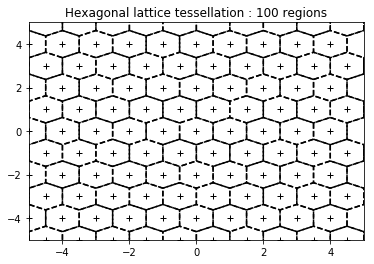

In [34]:
#### Nice hexagonal plot ###

boxsize, point_number, points, extended_points, vor, regions, vertices = create_test_vor_hex_reworked()

plot_full_polygons(regions_all_cclw, vertices)
plt.xlim(-boxsize/2.0, boxsize/2.0)
plt.ylim(-boxsize/2.0, boxsize/2.0)
plt.title('Hexagonal lattice tessellation : {} regions'.format(point_number))
for point in points:
    plt.plot(point[0],point[1], '+k')
plt.savefig("hexagonal_lattice_example.png")